# [GSE154992](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE154992)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-03-03
> - Modified: 2024-03-03

# 1. Experimental Design

> Combined analysis of ribo-seq and rna-seq reveals that Mettl3 regulates embryonic cerebral cortex development in mice by controlling the proliferation and differentiation of neural progenitor cells.
> - Du, K., Zhang, Z., Zeng, Z. et al. Distinct roles of Fto and Mettl3 in controlling development of the cerebral cortex through transcriptional and translational regulations. Cell Death Dis 12, 700 (2021). https://doi.org/10.1038/s41419-021-03992-2.
> - ribo(A) RNA-seq: NEBNext® UltraTM RNA Library Prep Kit from Illumina®
> - Ribo-seq: Treated with unspecific endoribonuclease RNase I
> - Illumina Novaseq, PE150
> - mm10

| Sample | Organism | Tissue | Genotype | Treatment | Fraction | Replicate |
| - | - | - | - | - | - | - |
| WT Ctrl mRNA | Mus musculus | Cerebral cortex | Wild Type | Control | Total RNA | rep1~3 |
| WT Ctrl Ribo | Mus musculus | Cerebral cortex | Wild Type | Control | Ribosome RNA | rep1~3 |
| Mettl3 cKO mRNA | Mus musculus | Cerebral cortex | Mettl3 flox/flox | Emx1-cre | Total RNA | rep1~3 |
| Mettl3 cKO Ribo | Mus musculus | Cerebral cortex | Mettl3 flox/flox | Emx1-cre | Ribosome RNA | rep1~3 |
| Fto cKO mRNA | Mus musculus | Cerebral cortex | Fto flox/flox | Emx1-cre | Total RNA | rep1~3 |
| Fto cKO Ribo | Mus musculus | Cerebral cortex | Fto flox/flox | Emx1-cre | Ribosome RNA | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(txdbmaker))
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicFeatures))
suppressPackageStartupMessages(library(GenomicAlignments))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/riboseq_Mm_Cortex_Mettl3_GSE154992/02_output_riboseq"

In [3]:
# load reference gene annotation
gtf_dir <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"

gtf <- rtracklayer::import(gtf_dir)

txdb <- txdbmaker::makeTxDbFromGFF(
    gtf_dir, 
    dataSource = "GENCODE", 
    organism = "Mus musculus", 
    taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "GENCODE Release"), 
        value = c("mm10", "vM23")))

txdb_pc <- txdbmaker::makeTxDbFromGRanges(
    gtf |> subset(gtf$gene_type == "protein_coding"), 
    taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "GENCODE Release", "Biotype"), 
        value = c("mm10", "vM23", "protein_coding")))

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”
OK

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 3. Quality Control

## 1). RPFs Length Distribution

> - Ribosome Protected Fragments (RPFs), 28 ~ 30 nt.
>   - View the ribotish output file, qual.pdf.
>   - View the ribotricer output file, read_length_dist.pdf. **\*\*\***



In [4]:
genome_bam <- file.path(
    data_dir, "03_align", "Cortex_WT_Ctrl_ribo_rep1.Aligned.out.bam") |>
    GenomicAlignments::readGAlignments()

genome_bam

GAlignments object with 39738139 alignments and 0 metadata columns:
             seqnames strand       cigar    qwidth     start       end
                <Rle>  <Rle> <character> <integer> <integer> <integer>
         [1]     chr9      +         28M        28 113880077 113880104
         [2]     chr4      -         25M        25 149222338 149222362
         [3]    chr16      -         27M        27  38618171  38618197
         [4]     chr2      -         29M        29 157040509 157040537
         [5]    chr11      +         28M        28  31061534  31061561
         ...      ...    ...         ...       ...       ...       ...
  [39738135]     chrX      +         27M        27 134605636 134605662
  [39738136]     chr2      -         23M        23  36036610  36036632
  [39738137]    chr14      -         25M        25 109107523 109107547
  [39738138]     chr6      -         27M        27  96033269  96033295
  [39738139]     chr9      +         29M        29 106461361 106461389
         

In [5]:
plot_df <- cigar(genome_bam) |> 
    cigarWidthAlongReferenceSpace(N.regions.removed = TRUE) |>
    table() |> as.data.frame() |>
    setNames(c("Length", "Count")) |>
    mutate(Length = as.numeric(as.character(Length)))

head(plot_df)

Warning message in call_new_fun_in_cigarillo("cigarWidthAlongReferenceSpace", "cigar_extent_along_ref", :
“cigarWidthAlongReferenceSpace() is formally deprecated in GenomicAlignments
  >= 1.45.5 and replaced with the cigar_extent_along_ref() function from the
  new cigarillo package”


,Length,Count
,<dbl>,<int>
1,20,456938
2,21,569535
3,22,700862
4,23,913326
5,24,1293001
6,25,3141968


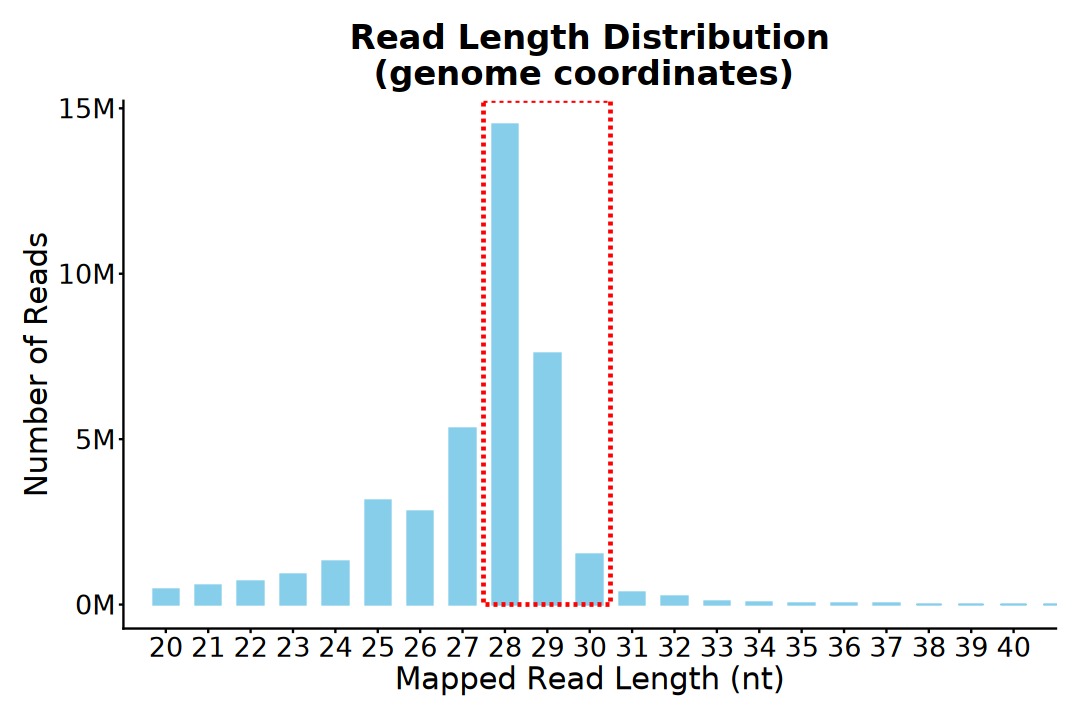

In [6]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Length, y = Count)) + 
    geom_bar(
        stat = "identity", color = "skyblue", fill = "skyblue", 
        width = 0.6) + 
    annotate(
        "rect", xmin = 27.5, xmax = 30.5, ymin = 0, ymax = Inf,
        color = "red", fill = "white", alpha = 0, 
        linewidth = 1, linetype = "dashed") +
    scale_x_continuous(breaks = c(20:40)) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M") ) +
    coord_cartesian(xlim = c(20, 40)) +
    labs(
        title = "Read Length Distribution\n(genome coordinates) ",
        x = "Mapped Read Length (nt)", y = "Number of Reads") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [7]:
transcript_bam <- file.path(
    data_dir, "03_align", "Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam") |>
    GenomicAlignments::readGAlignments()

transcript_bam

GAlignments object with 117035346 alignments and 0 metadata columns:
                           seqnames strand       cigar    qwidth     start
                              <Rle>  <Rle> <character> <integer> <integer>
          [1]  ENSMUST00000163895.2      +         28M        28      2129
          [2]  ENSMUST00000214522.1      +         28M        28      2122
          [3]  ENSMUST00000215022.1      +         28M        28      2085
          [4]  ENSMUST00000166734.9      +         28M        28      2068
          [5]  ENSMUST00000111838.9      +         28M        28      2080
          ...                   ...    ...         ...       ...       ...
  [117035342]  ENSMUST00000185507.6      +         29M        29       166
  [117035343]  ENSMUST00000217405.1      +         29M        29       177
  [117035344]  ENSMUST00000185779.6      +         29M        29       785
  [117035345]  ENSMUST00000215656.1      +         29M        29       549
  [117035346] ENSMUST0000002426

In [8]:
plot_df <- cigar(transcript_bam) |> 
    cigarWidthAlongReferenceSpace(N.regions.removed = TRUE) |>
    table() |> as.data.frame() |>
    setNames(c("Length", "Count")) |>
    mutate(Length = as.numeric(as.character(Length)))

Warning message in call_new_fun_in_cigarillo("cigarWidthAlongReferenceSpace", "cigar_extent_along_ref", :
“cigarWidthAlongReferenceSpace() is formally deprecated in GenomicAlignments
  >= 1.45.5 and replaced with the cigar_extent_along_ref() function from the
  new cigarillo package”


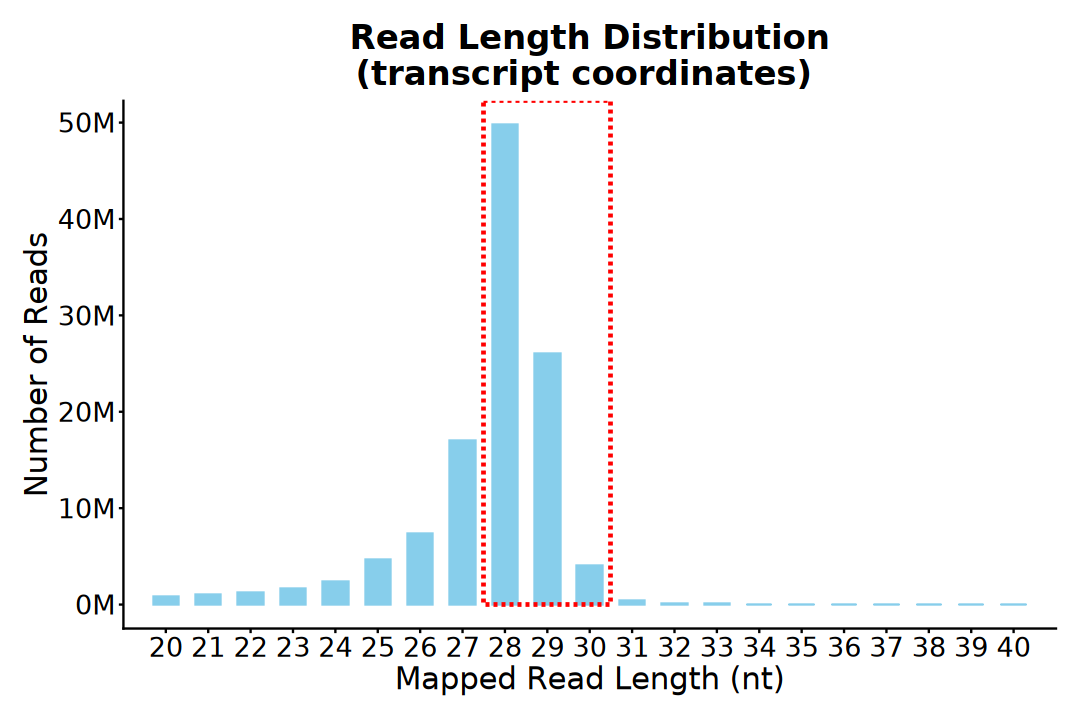

In [9]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Length, y = Count)) + 
    geom_bar(
        stat = "identity", color = "skyblue", fill = "skyblue", 
        width = 0.6) + 
    annotate(
        "rect", xmin = 27.5, xmax = 30.5, ymin = 0, ymax = Inf,
        color = "red", fill = "white", alpha = 0, 
        linewidth = 1, linetype = "dashed") +
    scale_x_continuous(breaks = c(20:40)) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M") ) +
    coord_cartesian(xlim = c(20, 40)) +
    labs(
        title = "Read Length Distribution\n(transcript coordinates) ",
        x = "Mapped Read Length (nt)", y = "Number of Reads") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [10]:
# ~ 2 min / sample
bam_files <- list.files(
    path = file.path(data_dir, "03_align"),
    pattern = "Aligned\\.toTranscriptome\\.out\\.bam$", 
    full.names = TRUE) |>
    set_names(\(x) basename(x) |> 
        gsub(".Aligned.toTranscriptome.out.bam", "", x = _))

plot_df <- bam_files |>
    map_dfr(.id = "Sample", function(file_path) {
        GenomicAlignments::readGAlignments(file_path) |>
            cigar() |> 
            cigarWidthAlongReferenceSpace(N.regions.removed = TRUE) |> 
            table() |> as.data.frame() |>
            setNames(c("Length", "Count")) |> 
            mutate(
                Length = as.numeric(as.character(Length)),
                Count = as.numeric(Count))
    })

Warning message in call_new_fun_in_cigarillo("cigarWidthAlongReferenceSpace", "cigar_extent_along_ref", :
“cigarWidthAlongReferenceSpace() is formally deprecated in GenomicAlignments
  >= 1.45.5 and replaced with the cigar_extent_along_ref() function from the
  new cigarillo package”
Warning message in call_new_fun_in_cigarillo("cigarWidthAlongReferenceSpace", "cigar_extent_along_ref", :
“cigarWidthAlongReferenceSpace() is formally deprecated in GenomicAlignments
  >= 1.45.5 and replaced with the cigar_extent_along_ref() function from the
  new cigarillo package”
Warning message in call_new_fun_in_cigarillo("cigarWidthAlongReferenceSpace", "cigar_extent_along_ref", :
“cigarWidthAlongReferenceSpace() is formally deprecated in GenomicAlignments
  >= 1.45.5 and replaced with the cigar_extent_along_ref() function from the
  new cigarillo package”
Warning message in call_new_fun_in_cigarillo("cigarWidthAlongReferenceSpace", "cigar_extent_along_ref", :
“cigarWidthAlongReferenceSpace() is for

In [11]:
plot_df <- plot_df |> 
    group_by(Sample) |> 
    mutate(Percentage = Count / sum(Count)) |>
    ungroup()

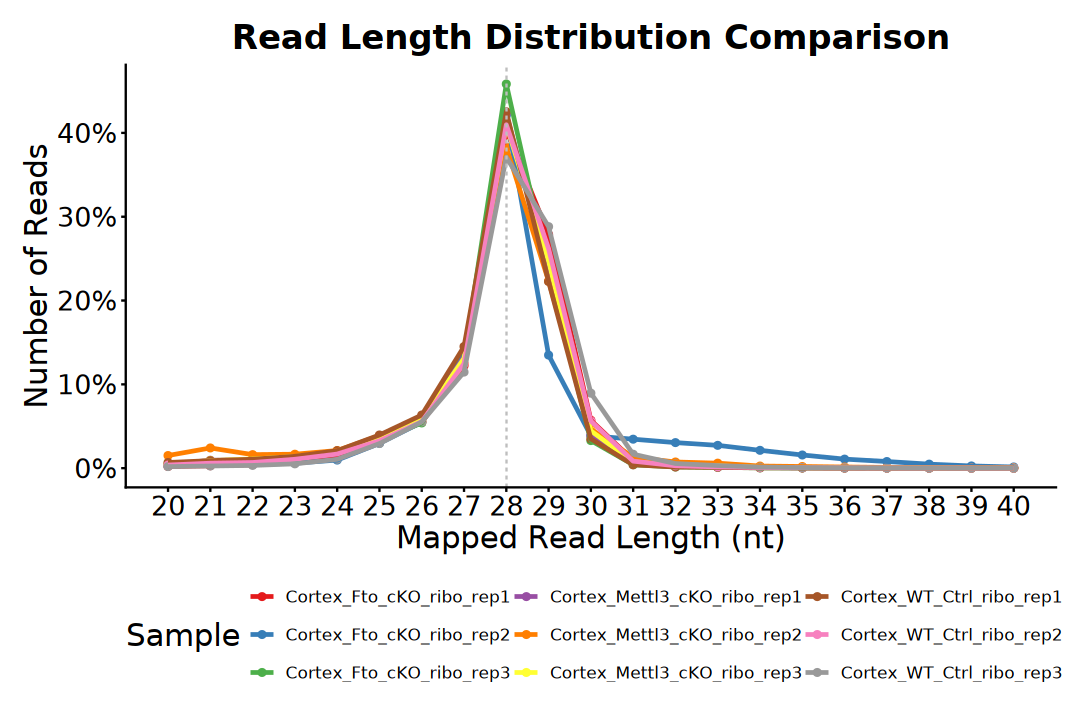

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Length, y = Percentage, color = Sample, group = Sample)) + 
    geom_point(size = 1.5) +
    geom_line(linewidth = 1) + 
    geom_vline(xintercept = 28, color = "gray", linetype = "dashed") +
    scale_color_brewer(palette = "Set1") + 
    # scale_color_viridis_d(option = "plasma") + 
    scale_x_continuous(breaks = c(20:40)) +
    scale_y_continuous(labels = scales::label_percent(accuracy = 1)) +
    coord_cartesian(xlim = c(20, 40)) +
    labs(
        title = "Read Length Distribution Comparison", 
        x = "Mapped Read Length (nt)", y = "Number of Reads",
        color = "Sample") + 
    guides(color = guide_legend(ncol = 3)) + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 10),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Footprint Validation

> - P-site Offset Calibration
> - Three-Nucleotide Periodicity
>   - View the ribotish output file, qual.pdf. **\*\*\***
>   - View the ribotricer output file, metagene_plots.pdf.

In [13]:
suppressPackageStartupMessages(library(riboWaltz))

In [14]:
source_dir <- file.path(data_dir, "03_align")
target_dir <- file.path(data_dir, "06_riboWaltz", "input")

dir.create(target_dir, recursive = TRUE, showWarnings = FALSE)

bam_files <- list.files(
    path = source_dir, 
    pattern = "\\.Aligned.toTranscriptome.out.bam$",
    full.names = FALSE)

message("Found ", length(bam_files), " BAM files to link.")

# sapply(bam_files, function(file_name) {
#     file.symlink(
#         from = file.path(source_dir, file_name),
#         to = file.path(target_dir, file_name))
# })

file.symlink(
    from = file.path(
        source_dir, "Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam"), 
    to = file.path(
        target_dir, "Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam")
)

Found 9 BAM files to link.

Warning message in file.symlink(from = file.path(source_dir, "Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam"), :
“cannot symlink '/home/fugui/dataset_1/bulk_omics/riboseq_Mm_Cortex_Mettl3_GSE154992/02_output_riboseq/03_align/Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam' to '/home/fugui/dataset_1/bulk_omics/riboseq_Mm_Cortex_Mettl3_GSE154992/02_output_riboseq/06_riboWaltz/input/Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam', reason 'File exists'”


[1] FALSE

### P-site Offset Calibration

In [15]:
create_annotation <- function (gtfpath = NULL, txdb = NULL, dataSource = NA, organism = NA) 
{
    if (length(gtfpath) != 0 & length(txdb) != 0) {
        cat("\n")
        warning("gtfpath and txdb are both specified. Only gtfpath will be considered\n")
        txdb = NULL
    }
    if (length(gtfpath) == 0 & length(txdb) == 0) {
        cat("\n")
        stop("neither gtfpath nor txdb is specified\n\n")
    }
    if (length(gtfpath) != 0) {
        path_to_gtf <- gtfpath
        txdbanno <- txdbmaker::makeTxDbFromGFF(file = path_to_gtf, 
            format = "gtf", dataSource = dataSource, organism = organism)
    }
    else {
        if (txdb %in% rownames(installed.packages())) {
            library(txdb, character.only = TRUE)
        }
        else {
            source("https://bioconductor.org/biocLite.R")
            biocLite(txdb, suppressUpdates = TRUE)
            library(txdb, character.only = TRUE)
        }
        txdbanno <- get(txdb)
    }
    exon <- suppressWarnings(GenomicFeatures::exonsBy(txdbanno, 
        by = "tx", use.names = T))
    utr5 <- suppressWarnings(GenomicFeatures::fiveUTRsByTranscript(txdbanno, 
        use.names = T))
    cds <- suppressWarnings(GenomicFeatures::cdsBy(txdbanno, 
        by = "tx", use.names = T))
    utr3 <- suppressWarnings(GenomicFeatures::threeUTRsByTranscript(txdbanno, 
        use.names = T))
    exon <- data.table::as.data.table(exon[unique(names(exon))])
    utr5 <- data.table::as.data.table(utr5[unique(names(utr5))])
    cds <- data.table::as.data.table(cds[unique(names(cds))])
    utr3 <- data.table::as.data.table(utr3[unique(names(utr3))])
    anno_df <- exon[, list(l_tr = sum(width)), by = list(transcript = group_name)]
    l_utr5 <- utr5[, list(l_utr5 = sum(width)), by = list(transcript = group_name)]
    l_cds <- cds[, list(l_cds = sum(width)), by = list(transcript = group_name)]
    l_utr3 <- utr3[, list(l_utr3 = sum(width)), by = list(transcript = group_name)]
    merge_allx <- function(x, y) merge(x, y, all.x = TRUE)
    anno_df <- Reduce(merge_allx, list(anno_df, l_utr5, l_cds, 
        l_utr3))
    anno_df[is.na(anno_df)] <- 0
    return(anno_df)
}

In [16]:
annotation_dt <- create_annotation(
    gtf_dir, dataSource = "GENCODE", organism = "Mus musculus")

head(annotation_dt)

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”
OK



transcript,l_tr,l_utr5,l_cds,l_utr3
<chr>,<int>,<dbl>,<dbl>,<dbl>
ENSMUST00000000001.4,3262,141,1065,2056
ENSMUST00000000003.13,902,140,525,237
ENSMUST00000000010.8,2574,85,753,1736
ENSMUST00000000028.13,2143,313,1701,129
ENSMUST00000000033.11,3708,115,543,3050
ENSMUST00000000049.5,1190,51,1038,101


In [17]:
name_of_bams <- "WT_Ctrl_rep1"
names(name_of_bams) <- "Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out"

In [18]:
# ~ 4 min / sample
reads_list <- bamtolist(
    bamfolder = file.path(data_dir, "06_riboWaltz", "input"), 
    name_samples = name_of_bams,
    annotation = annotation_dt, output_class = "granges")

Reading Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam
Input reads: 117.035 M
Good! Number of indel below indel_threshold for all reads. No reads removed.
Great! All reads' reference transcript IDs were found in the annotation table. No reads removed.
0.930 M  (0.794 %) reads removed: mapping on negative strand.
Output reads: 116.106 M
Done! Cortex_WT_Ctrl_ribo_rep1.Aligned.toTranscriptome.out.bam has been loaded as WT_Ctrl_rep1 



In [19]:
reads_list$WT_Ctrl_rep1

GRanges object with 116105815 ranges and 3 metadata columns:
                           seqnames    ranges strand |    length cds_start
                              <Rle> <IRanges>  <Rle> | <integer> <numeric>
          [1]  ENSMUST00000163895.2 2129-2156      + |        28       134
          [2]  ENSMUST00000214522.1 2122-2149      + |        28       136
          [3]  ENSMUST00000215022.1 2085-2112      + |        28       136
          [4]  ENSMUST00000166734.9 2068-2095      + |        28       136
          [5]  ENSMUST00000111838.9 2080-2107      + |        28       148
          ...                   ...       ...    ... .       ...       ...
  [116105811]  ENSMUST00000185507.6   166-194      + |        29         1
  [116105812]  ENSMUST00000217405.1   177-205      + |        29         0
  [116105813]  ENSMUST00000185779.6   785-813      + |        29       302
  [116105814]  ENSMUST00000215656.1   549-577      + |        29       183
  [116105815] ENSMUST00000024260.13   7

In [20]:
# ! Warning in length_filter
# filtered_list <- length_filter(
#     data = reads_list, length_filter_mode = "custom", 
#     length_range = 28:32)

filtered_list <- lapply(
    reads_list, subset, length >= 28 & length <= 30)

In [21]:
print(length(reads_list$WT_Ctrl_rep1))
print(length(filtered_list$WT_Ctrl_rep1))

[1] 116105815
[1] 79531403


In [22]:
# Identifies the exact position of the ribosome P-site within each read, 
# determined by the localisation of its first nucleotide
psite_offset <- psite(filtered_list, flanking = 6, extremity = "auto")
psite_offset |> t() |> print()

processing WT_Ctrl_rep1
best offset: 12 nts from the 5' end
                        [,1]           [,2]           [,3]          
length                  "28"           "29"           "30"          
total_percentage        "62.303"       "32.614"       " 5.082"      
start_percentage        "57.075"       "36.823"       " 6.102"      
around_start            "T"            "T"            "T"           
offset_from_5           "12"           "12"           "12"          
offset_from_3           "15"           "16"           "17"          
corrected_offset_from_5 "12"           "12"           "12"          
corrected_offset_from_3 "15"           "16"           "17"          
sample                  "WT_Ctrl_rep1" "WT_Ctrl_rep1" "WT_Ctrl_rep1"


In [23]:
reads_psite_list <- psite_info(filtered_list, psite_offset)

processing WT_Ctrl_rep1
1. adding p-site position
2. adding transcript region


In [24]:
head(reads_psite_list$WT_Ctrl_rep1)

transcript,end5,psite,end3,length,cds_start,cds_stop,psite_from_start,psite_from_stop,psite_region
<chr>,<int>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
ENSMUST00000000001.4,85,97,112,28,142,1206,-45,-1109,5utr
ENSMUST00000000001.4,94,106,122,29,142,1206,-36,-1100,5utr
ENSMUST00000000001.4,97,109,124,28,142,1206,-33,-1097,5utr
ENSMUST00000000001.4,97,109,125,29,142,1206,-33,-1097,5utr
ENSMUST00000000001.4,97,109,125,29,142,1206,-33,-1097,5utr
ENSMUST00000000001.4,141,153,169,29,142,1206,11,-1053,cds


### Three-Nucleotide Periodicity

In [25]:
psite_df <- reads_psite_list[[1]]

In [26]:
start_codon_reads <- psite_df[
    !is.na(psite_df$psite_region) & abs(psite_df$psite_from_start) <= 50,]

plot_df <- start_codon_reads$psite_from_start |>
    table() |> as.data.frame(stringsAsFactors = FALSE) |> 
    setNames(c("Pos", "Freq")) |>
    mutate(
        Pos = as.numeric(as.character(Pos)),
        Color = ifelse(
            Pos %% 3 == 0, "red", ifelse(
                Pos %% 3 == 1, "green", "blue")))

head(plot_df)

,Pos,Freq,Color
,<dbl>,<int>,<chr>
1,-50,6660,green
2,-49,7077,blue
3,-48,10666,red
4,-47,7818,green
5,-46,7968,blue
6,-45,13999,red


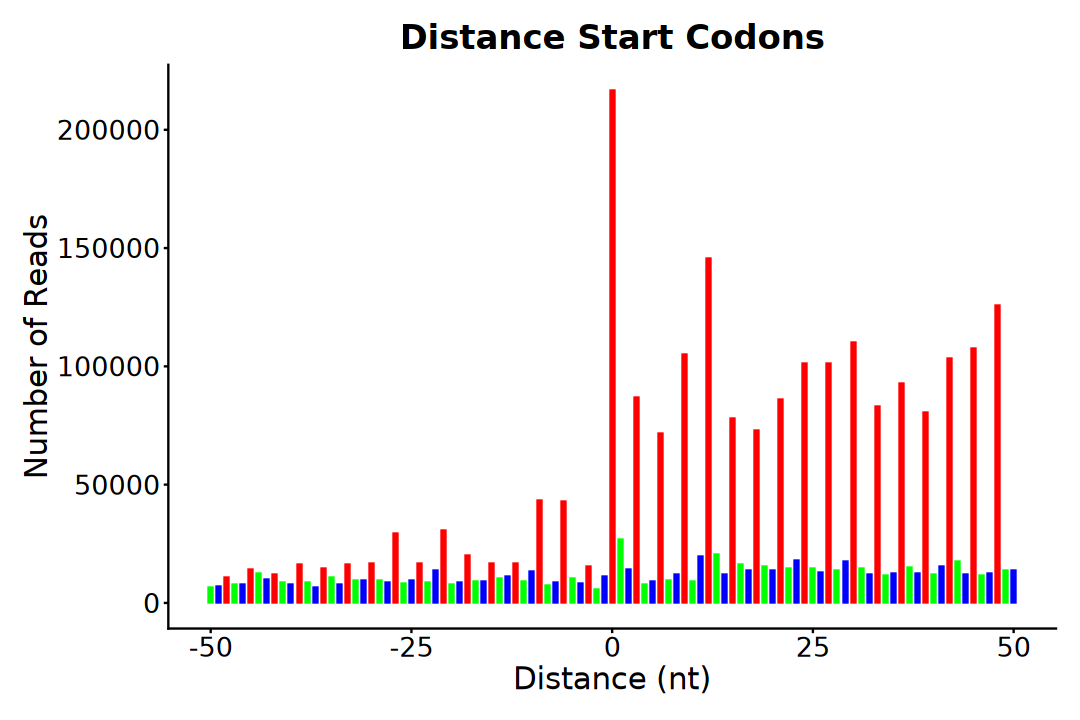

In [27]:
options(repr.plot.width=9, repr.plot.height=6)
ggplot(plot_df, aes(x = Pos, y = Freq, fill = Color, color = Color)) +
    geom_bar(stat = "identity", width = 0.5) + 
    scale_fill_manual(
        values = c(red = "red", blue = "blue",  green = "green")) +
    scale_color_manual(
        values = c(red = "red", blue = "blue",  green = "green")) +
    labs(
        title = "Distance Start Codons", 
        x = "Distance (nt)", y = "Number of Reads") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [28]:
stop_codon_reads <- psite_df[
    !is.na(psite_df$psite_region) & abs(psite_df$psite_from_stop) <= 50,]

plot_df <- stop_codon_reads$psite_from_stop |>
    table() |> as.data.frame(stringsAsFactors = FALSE) |> 
    setNames(c("Pos", "Freq")) |>
    mutate(
        Pos = as.numeric(as.character(Pos)),
        Color = ifelse(
            Pos %% 3 == 0, "blue", ifelse(
                Pos %% 3 == 1, "red", "green")))

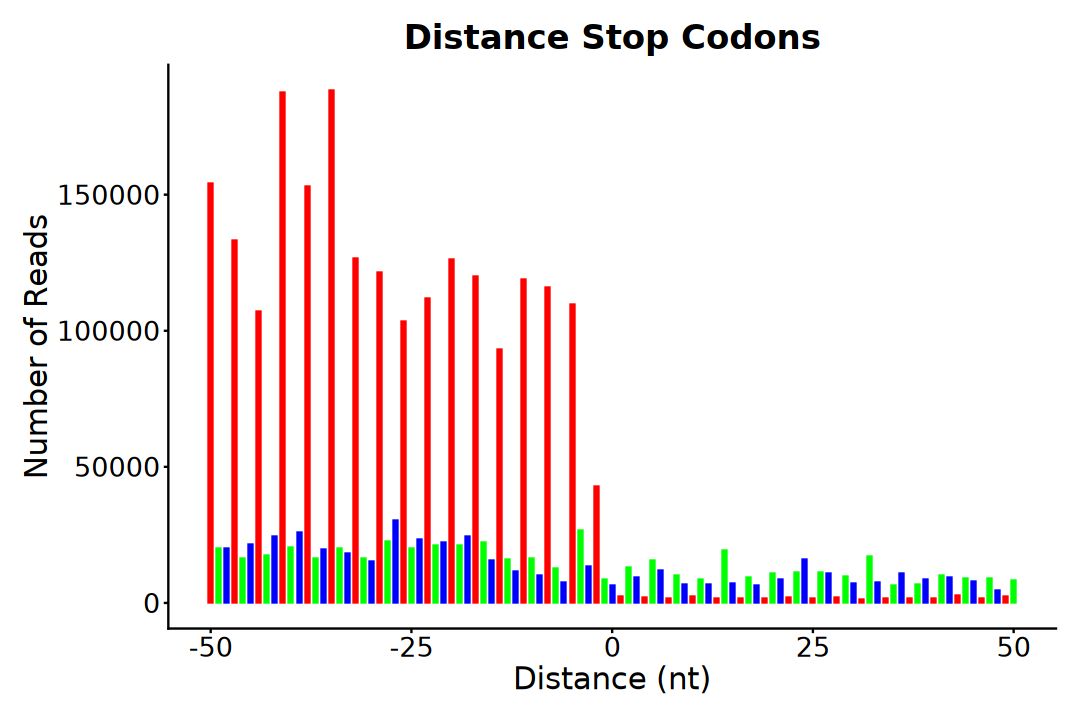

In [29]:
options(repr.plot.width=9, repr.plot.height=6)
ggplot(plot_df, aes(x = Pos, y = Freq, fill = Color, color = Color)) +
    geom_bar(stat = "identity", width = 0.5) + 
    scale_fill_manual(
        values = c(red = "red", blue = "blue",  green = "green")) +
    scale_color_manual(
        values = c(red = "red", blue = "blue",  green = "green")) +
    labs(
        title = "Distance Stop Codons", 
        x = "Distance (nt)", y = "Number of Reads") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Reading Frame Bias

In [30]:
plot_df <- psite_df$psite_region |> 
    table(useNA = "always") |>
    as.data.frame(stringsAsFactors = FALSE) |> 
    setNames(c("Feature", "Freq")) |>
    mutate(
        Feature = ifelse(is.na(Feature), "Intron", Feature),
        Feature = factor(Feature, levels = c(
            "cds", "5utr", "3utr", "Intron"))) |>
    arrange(desc(Feature)) |>
    mutate(
        Fraction = Freq / sum(Freq),
        Percent  = scales::percent(Fraction),
        Pos = cumsum(Freq) - 0.5 * Freq)

plot_df

Feature,Freq,Fraction,Percent,Pos
<fct>,<int>,<dbl>,<chr>,<dbl>
Intron,16785541,0.21105551,21.1%,8392770
3utr,3833921,0.04820638,4.8%,18702502
5utr,2015343,0.02534022,2.5%,21627134
cds,56896598,0.71539789,71.5%,51083104


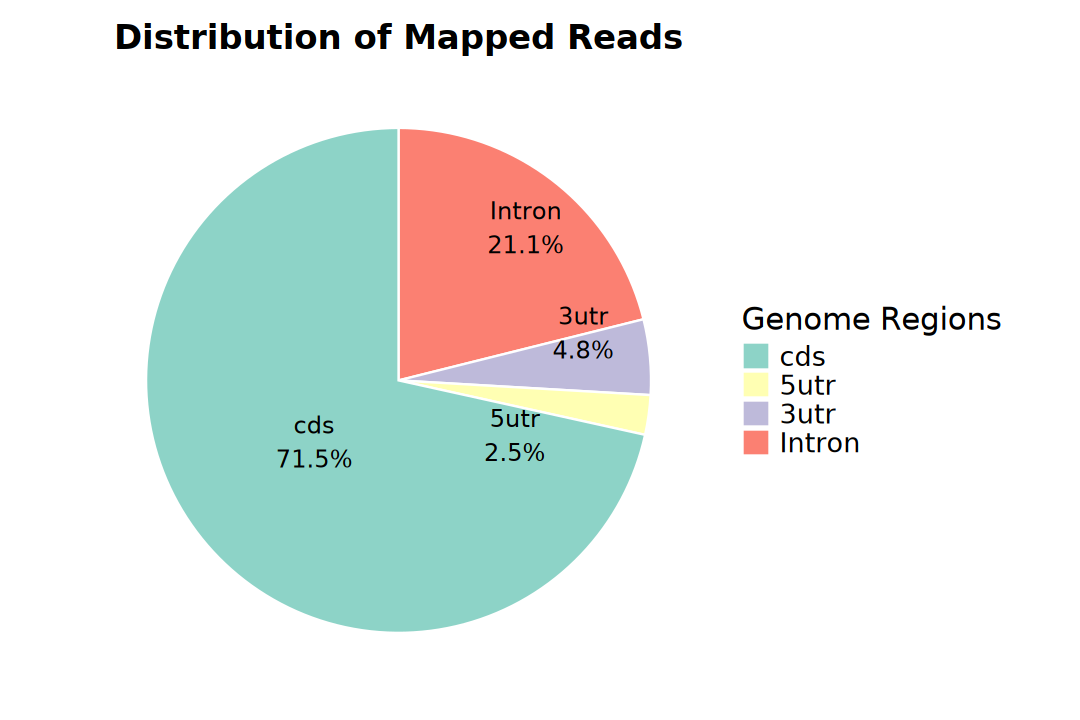

In [31]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = "", y = Freq, fill = Feature)) + 
    geom_bar(width = 1, stat = "identity", color = "white") +
    ggrepel::geom_text_repel(
        aes(x = 1.1, y = Pos, label = paste0(Feature, "\n", Percent)), 
        size = 5, segment.color = "grey50", show.legend = FALSE) +
    coord_polar("y", start = 0) +
    scale_fill_brewer(palette = "Set3") +
    labs(
        title = "Distribution of Mapped Reads", 
        fill = "Genome Regions") +
    theme_minimal() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid = element_blank(),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks = element_blank())

## 3). RPFs Genomic Feature Distribution

In [32]:
suppressPackageStartupMessages(library(ChIPseeker))
suppressPackageStartupMessages(library(org.Mm.eg.db))

In [33]:
genome_reads <- GRanges(genome_bam)
total_reads <- length(genome_reads)

set.seed(123)
sampled_indices <- sample(total_reads, size = floor(total_reads * 0.01))

genome_reads_sampled <- genome_reads[sampled_indices]
genome_reads_sampled

GRanges object with 397381 ranges and 0 metadata columns:
           seqnames              ranges strand
              <Rle>           <IRanges>  <Rle>
       [1]    chr19     7204392-7204419      -
       [2]    chr12   12362330-12362357      +
       [3]    chr11   30139264-30139292      -
       [4]     chrX   49757661-49757689      -
       [5]     chr5 104486456-104486480      -
       ...      ...                 ...    ...
  [397377]     chr1 182527950-182633806      -
  [397378]     chr3 124929800-124929823      +
  [397379]     chr7 127194517-127194545      -
  [397380]     chr4 109046612-109046640      +
  [397381]     chr1     7120322-7120349      +
  -------
  seqinfo: 66 sequences from an unspecified genome

In [34]:
# ~ 20 min / all reads
unique_reads_anno <- annotatePeak(
    genome_reads_sampled, tssRegion=c(0, 1), level = "transcript", 
    TxDb = txdb_pc, annoDb="org.Mm.eg.db", 
    genomicAnnotationPriority = c(
        "5UTR", "3UTR", "Exon", "Intron", "Intergenic"))

>> preparing features information...		 2026-06-26 22:29:13 
>> Using Genome: mm10 ...
>> identifying nearest features...		 2026-06-26 22:29:14 
>> calculating distance from peak to TSS...	 2026-06-26 22:29:16 
>> assigning genomic annotation...		 2026-06-26 22:29:16 
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> adding gene annotation...			 2026-06-26 22:29:27 


'select()' returned 1:many mapping between keys and columns



>> assigning chromosome lengths			 2026-06-26 22:29:28 
>> done...					 2026-06-26 22:29:28 


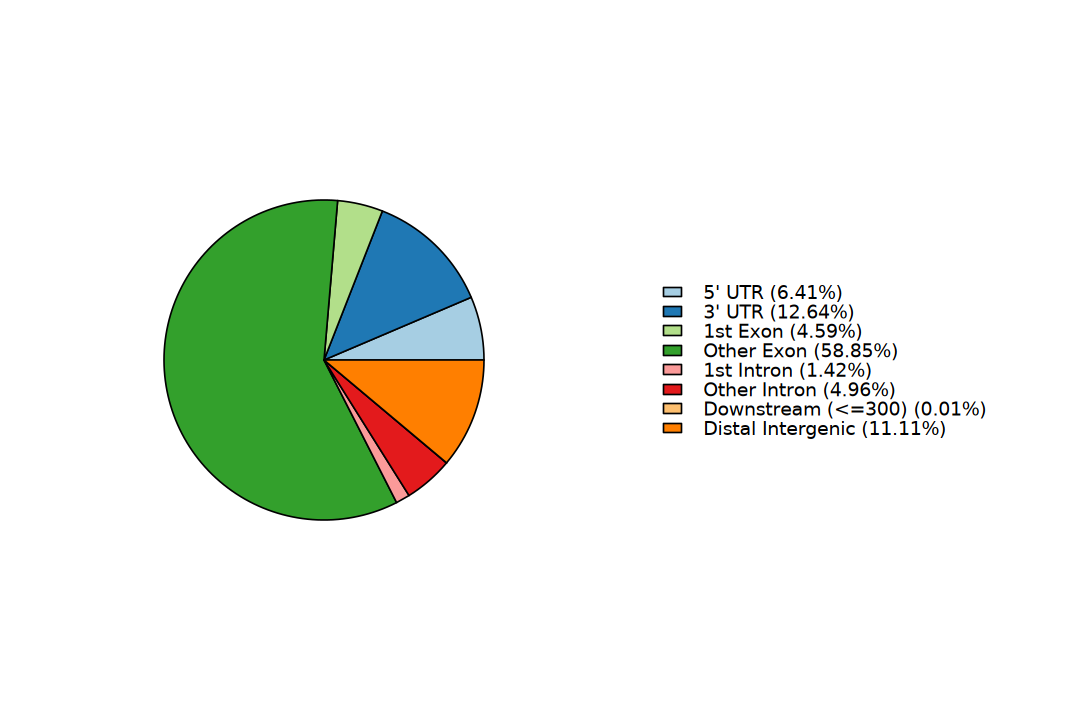

In [35]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoPie(unique_reads_anno)

In [36]:
cds <- unlist(cdsBy(txdb_pc))
utr5 <- unlist(fiveUTRsByTranscript(txdb_pc))
utr3 <- unlist(threeUTRsByTranscript(txdb_pc))
intron <- unlist(intronsByTranscript(txdb_pc))

In [37]:
genome_reads_sampled$feature <- "Intergenic"

hit_cds   <- queryHits(findOverlaps(genome_reads_sampled, cds))
hit_utr5  <- queryHits(findOverlaps(genome_reads_sampled, utr5))
hit_utr3  <- queryHits(findOverlaps(genome_reads_sampled, utr3))
hit_intro <- queryHits(findOverlaps(genome_reads_sampled, intron))

genome_reads_sampled$feature[hit_intro] <- "Intron"
genome_reads_sampled$feature[hit_utr3]  <- "3'UTR"
genome_reads_sampled$feature[hit_utr5]  <- "5'UTR"
genome_reads_sampled$feature[hit_cds]   <- "CDS"

In [38]:
plot_df <- table(genome_reads_sampled$feature) |> 
    as.data.frame(, stringsAsFactors = FALSE) |> 
    setNames(c("Feature", "Freq")) |>
    mutate(
        Feature = factor(Feature, levels = c(
            "CDS", "5'UTR", "3'UTR", "Intron", "Intergenic"))) |>
    arrange(desc(Feature)) |>
    mutate(
        Fraction = Freq / sum(Freq),
        Percent  = scales::percent(Fraction),
        Pos = cumsum(Freq) - 0.5 * Freq)

plot_df

Feature,Freq,Fraction,Percent,Pos
<fct>,<int>,<dbl>,<chr>,<dbl>
Intergenic,57798,0.145447316,14.5%,28899.0
Intron,16190,0.040741757,4.1%,65893.0
3'UTR,2273,0.005719951,0.6%,75124.5
5'UTR,9696,0.024399757,2.4%,81109.0
CDS,311424,0.783691218,78.4%,241669.0


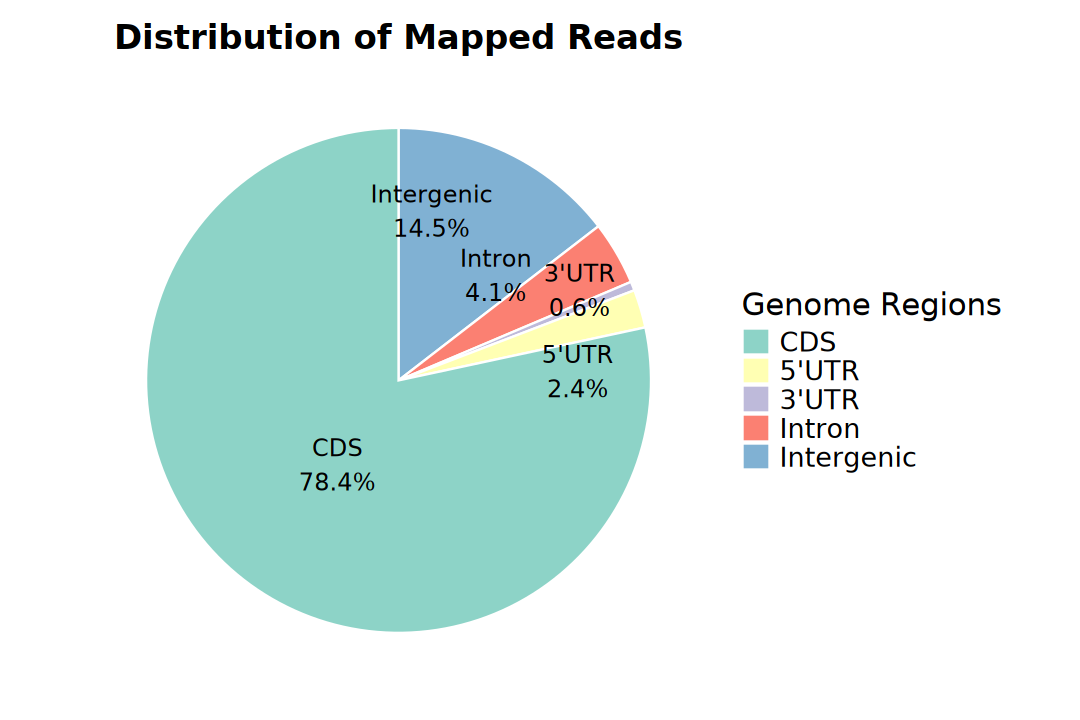

In [39]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = "", y = Freq, fill = Feature)) + 
    geom_bar(width = 1, stat = "identity", color = "white") +
    ggrepel::geom_text_repel(
        aes(x = 1.1, y = Pos, label = paste0(Feature, "\n", Percent)), 
        size = 5, segment.color = "grey50", show.legend = FALSE) +
    coord_polar("y", start = 0) +
    scale_fill_brewer(palette = "Set3") +
    labs(
        title = "Distribution of Mapped Reads", 
        fill = "Genome Regions") +
    theme_minimal() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid = element_blank(),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks = element_blank())

In [40]:
suppressPackageStartupMessages(library(Biostrings))

In [41]:
transcript_seq <- readDNAStringSet(
    "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa")

transcript_seq

DNAStringSet object of length 142351:
          width seq                                         names               
     [1]   1070 AAGGAAAGAGGATAACACTT...GGTATAAAGTTAGAGAAATG ENSMUST0000019381...
     [2]    110 GTGCTTGCTTCGGCAACACA...ATATTGAGTAACAAAAATAT ENSMUST0000008290...
     [3]   4153 GCACACTACGGTCCATCTCC...AATTAATCTCTGCCACTCCA ENSMUST0000016289...
     [4]   2989 TTAGTTAAGAGCACTGACTG...AAGGTGAAAATGAAGTTGTC ENSMUST0000015926...
     [5]   3634 GCGGCGGCGGGCGAGCGGGC...AAAAGTGCCGGTCAAACTTT ENSMUST0000007053...
     ...    ... ...
[142347]    519 ATGAATAATTATATTTTTGT...TCGAGATTACTCGAGATTAA ENSMUST0000008241...
[142348]     69 GTTTCTGTAGTTGAATTACA...TTGAATGCTGTGTAGAAATA ENSMUST0000008242...
[142349]   1144 ATGACAAACATACGAAAAAC...AATACTAAAATTATATCCAT ENSMUST0000008242...
[142350]     67 GTCTTGATAGTATAAACATT...GATCTTCTCTTCTCAAGACA ENSMUST0000008242...
[142351]     67 CAAGAAGTAGTTTAATTAGA...GAGTAGCTCCTTCTTCTTGA ENSMUST0000008242...

In [42]:
header_matrix <- str_split_fixed(
    names(transcript_seq), "\\|", n = 9)

head(header_matrix)

names(transcript_seq) <- header_matrix[, 1]

ENSMUST00000193812.1,ENSMUSG00000102693.1,OTTMUSG00000049935.1,OTTMUST00000127109.1,4933401J01Rik-201,4933401J01Rik,1070,TEC,
ENSMUST00000082908.1,ENSMUSG00000064842.1,-,-,Gm26206-201,Gm26206,110,snRNA,
ENSMUST00000162897.1,ENSMUSG00000051951.5,OTTMUSG00000026353.2,OTTMUST00000086625.1,Xkr4-203,Xkr4,4153,lncRNA,
ENSMUST00000159265.1,ENSMUSG00000051951.5,OTTMUSG00000026353.2,OTTMUST00000086624.1,Xkr4-202,Xkr4,2989,lncRNA,
ENSMUST00000070533.4,ENSMUSG00000051951.5,OTTMUSG00000026353.2,OTTMUST00000065166.1,Xkr4-201,Xkr4,3634,protein_coding,
ENSMUST00000192857.1,ENSMUSG00000102851.1,OTTMUSG00000049958.1,OTTMUST00000127143.1,Gm18956-201,Gm18956,480,processed_pseudogene,


In [43]:
psite_cds_df <- psite_df |> filter(psite_region == "cds")

psite_cds_seq <- subseq(
    transcript_seq[psite_cds_df$transcript], 
    start = psite_cds_df$psite, 
    end = psite_cds_df$psite + 2
)

psite_cds_seq

DNAStringSet object of length 56896598:
           width seq                                        names               
       [1]     3 GTT                                        ENSMUST00000000001.4
       [2]     3 GTT                                        ENSMUST00000000001.4
       [3]     3 TTG                                        ENSMUST00000000001.4
       [4]     3 TTG                                        ENSMUST00000000001.4
       [5]     3 TTG                                        ENSMUST00000000001.4
       ...   ... ...
[56896594]     3 TCC                                        ENSMUST00000239169.1
[56896595]     3 TCC                                        ENSMUST00000239169.1
[56896596]     3 CAG                                        ENSMUST00000239169.1
[56896597]     3 CAG                                        ENSMUST00000239169.1
[56896598]     3 CAG                                        ENSMUST00000239169.1

## 4). Codon Occupancy

In [44]:
codon_counts <- as.character(psite_cds_seq) |> 
    table() |> as.data.frame() |> 
    setNames(c("Codon", "Count")) |>
    mutate(Codon = gsub("T", "U", Codon)) |>
    filter(nchar(Codon) == 3) |>
    mutate(Percentage = Count / sum(Count)) |>
    arrange(desc(Percentage))

head(codon_counts)

,Codon,Count,Percentage
,<chr>,<int>,<dbl>
1,CUG,3058145,0.05374917
2,GAG,2567872,0.04513226
3,GAC,2067408,0.03633623
4,GUG,1969466,0.03461483
5,GAA,1963845,0.03451604
6,CAG,1836910,0.03228506


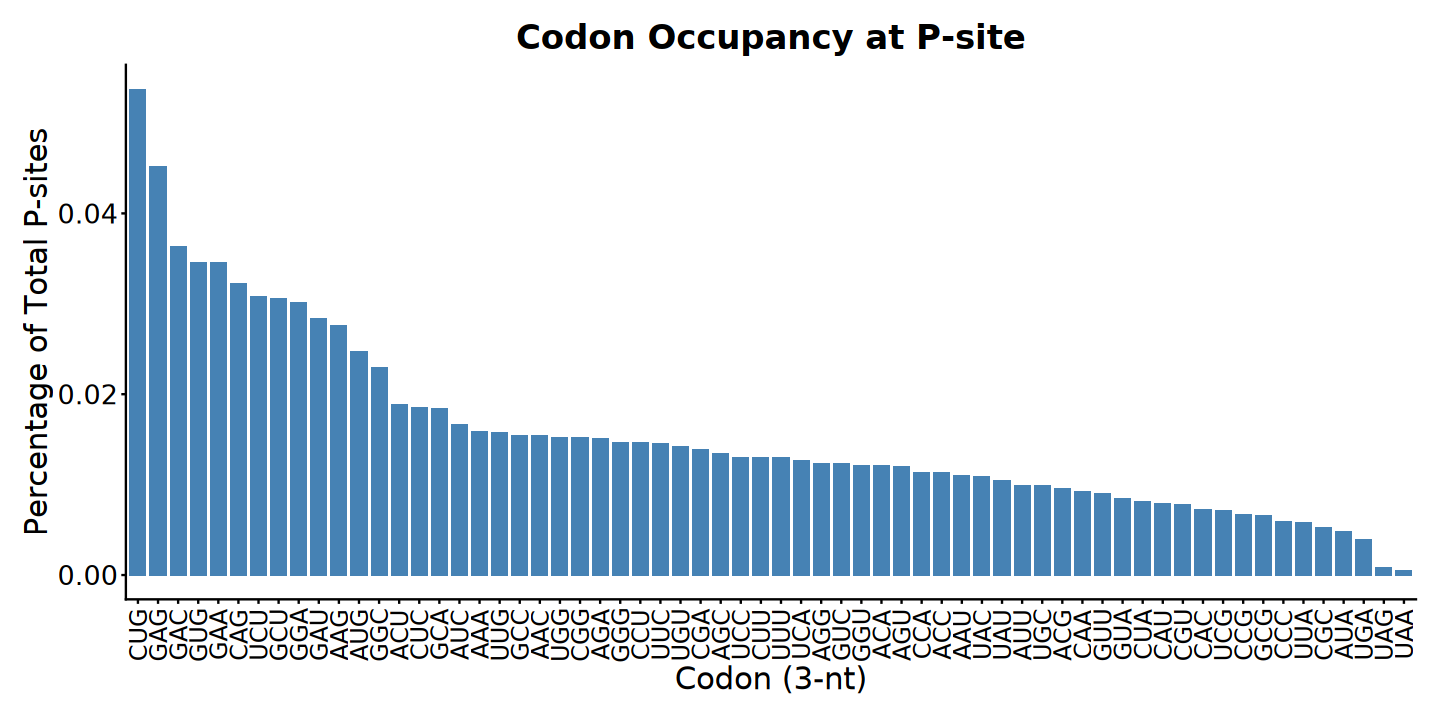

In [45]:
options(repr.plot.width = 12, repr.plot.height = 6)

ggplot(codon_counts, aes(x = reorder(Codon, -Percentage), y = Percentage)) + 
    geom_col(fill = "steelblue", width = 0.8) +
    # scale_x_continuous(breaks = c(20:40)) +
    # scale_y_continuous(
    #     labels = scales::label_number(scale = 1e-6, suffix = "M") ) +
    # coord_cartesian(xlim = c(20, 40)) +
    labs(
        title = "Codon Occupancy at P-site",
        x = "Codon (3-nt)", y = "Percentage of Total P-sites") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 14, angle = 90, vjust = 0.5),
        axis.text.y = element_text(size = 16))

## 5). Base Composition per Position

In [46]:
seq_matrix <- as.matrix(psite_cds_seq)

pos_basis <- lapply(1:3, function(pos) {
    table(seq_matrix[, pos]) |>
        as.data.frame() |>
        setNames(c("Base", "Count")) |>
        mutate(Position = paste0("Pos ", pos))
}) |> bind_rows() |>
    group_by(Position) |>
    mutate(Percentage = Count / sum(Count)) |>
    ungroup()

head(pos_basis)

Base,Count,Position,Percentage
<fct>,<int>,<chr>,<dbl>
A,13127760,Pos 1,0.2307301
C,13131007,Pos 1,0.2307872
G,20468653,Pos 1,0.3597518
T,10169178,Pos 1,0.1787309
A,16710625,Pos 2,0.2937017
C,12812004,Pos 2,0.2251805


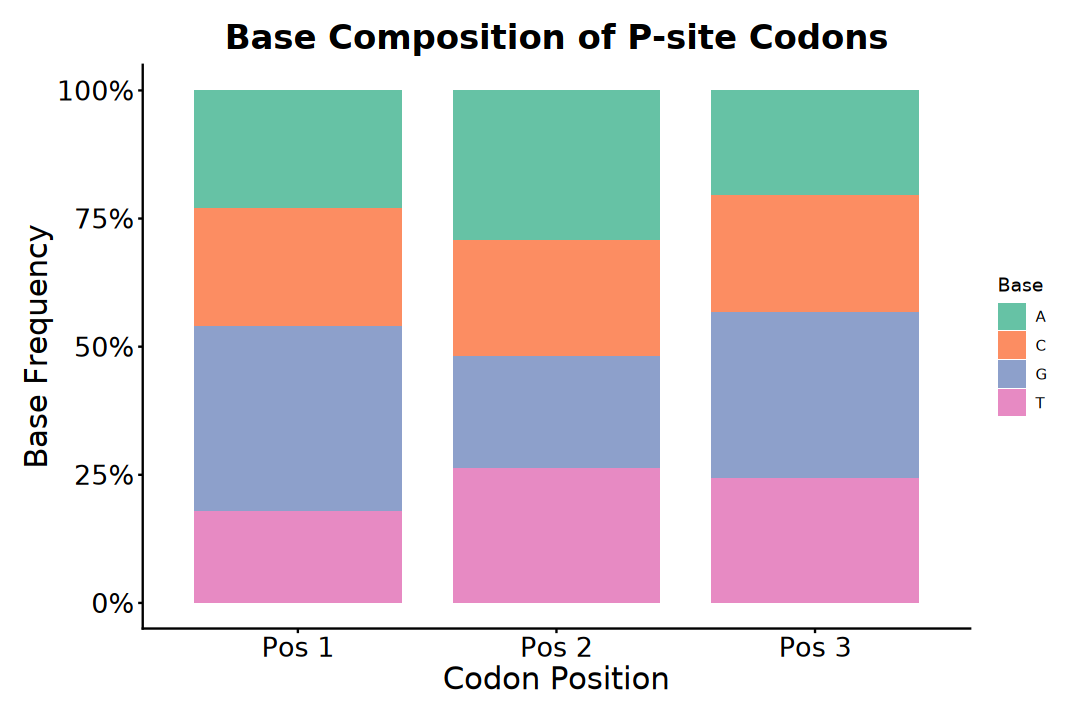

In [47]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pos_basis, aes(x = Position, y = Percentage, fill = Base)) + 
    geom_col(position = "stack", width = 0.8) +
    scale_y_continuous(labels = scales::label_percent()) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Base Composition of P-site Codons",
        x = "Codon Position", y = "Base Frequency") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## [RiboProfiling](https://www.bioconductor.org/packages/release/bioc/html/RiboProfiling.html)

In [48]:
# suppressPackageStartupMessages(library(RiboProfiling))

In [49]:
# bam_files <- list.files(
#     path = file.path(data_dir, "03_align"),
#     pattern = "Aligned\\.toTranscriptome\\.out\\.bam$", 
#     full.names = TRUE
# ) |>
#     set_names(\(x) basename(x) |> 
#         gsub(".Aligned.toTranscriptome.out.bam", "", x = _))

In [50]:
# cov_data <- riboSeqFromBAM(
#     bam_files[c(7, 4, 1)], genomeName = "mm10", txdb = txdb)

> - [riboSeqR](https://www.bioconductor.org/packages//release/bioc/html/riboSeqR.html)

# 4. Non-canonical ORFs

> Open Reading Frames (ORFs)

## a). [Ribo-TISH](https://github.com/zhpn1024/ribotish)

In [51]:
orfs_files_list <- file.path(data_dir, "06_ribotish") |>
    list.files("pred.longest.txt", full.names = TRUE)

In [52]:
orfs <- data.table::fread(
    orfs_files_list[[1]], header = TRUE, sep = "\t", 
    drop = c("Seq"))

head(orfs)

Gid,Tid,Symbol,GeneType,GenomePos,StartCodon,Start,Stop,TisType,TISGroup,TISCounts,TISPvalue,RiboPvalue,RiboPStatus,FisherPvalue,TISQvalue,FrameQvalue,FisherQvalue,AALen,InFrameCount
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<int>,<int>,<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,<int>,<int>
ENSMUSG00000051951.5,ENSMUST00000070533.4,Xkr4,protein_coding,chr1:3216021-3671348:-,ATG,150,2094,Annotated,0,0,None,1.708563e-09,N,None,None,1.819021e-08,None,647,41
ENSMUSG00000025902.13,ENSMUST00000027035.9,Sox17,protein_coding,chr1:4491715-4493406:-,ATG,1082,2342,Annotated,0,0,None,2.220654e-03,N,None,None,1.323269e-02,None,419,8
ENSMUSG00000025902.13,ENSMUST00000116652.7,Sox17,protein_coding,chr1:4491715-4493406:-,ATG,249,1509,Annotated,0,0,None,2.220654e-03,N,None,None,1.323269e-02,None,419,8
ENSMUSG00000033813.15,ENSMUST00000165720.2,Tcea1,protein_coding,chr1:4858407-4896364:+,ATG,370,1309,Annotated,0,0,None,6.111832e-03,N,None,None,3.412727e-02,None,312,628
ENSMUSG00000033845.13,ENSMUST00000130201.7,Mrpl15,protein_coding,chr1:4774451-4785677:-,ATG,33,648,Annotated,0,0,None,1.344593e-17,N,None,None,2.431208e-16,None,204,384
ENSMUSG00000033845.13,ENSMUST00000156816.6,Mrpl15,protein_coding,chr1:4776463-4785677:-,ATG,62,950,Annotated,0,0,None,5.753746e-28,N,None,None,1.741289e-26,None,295,867


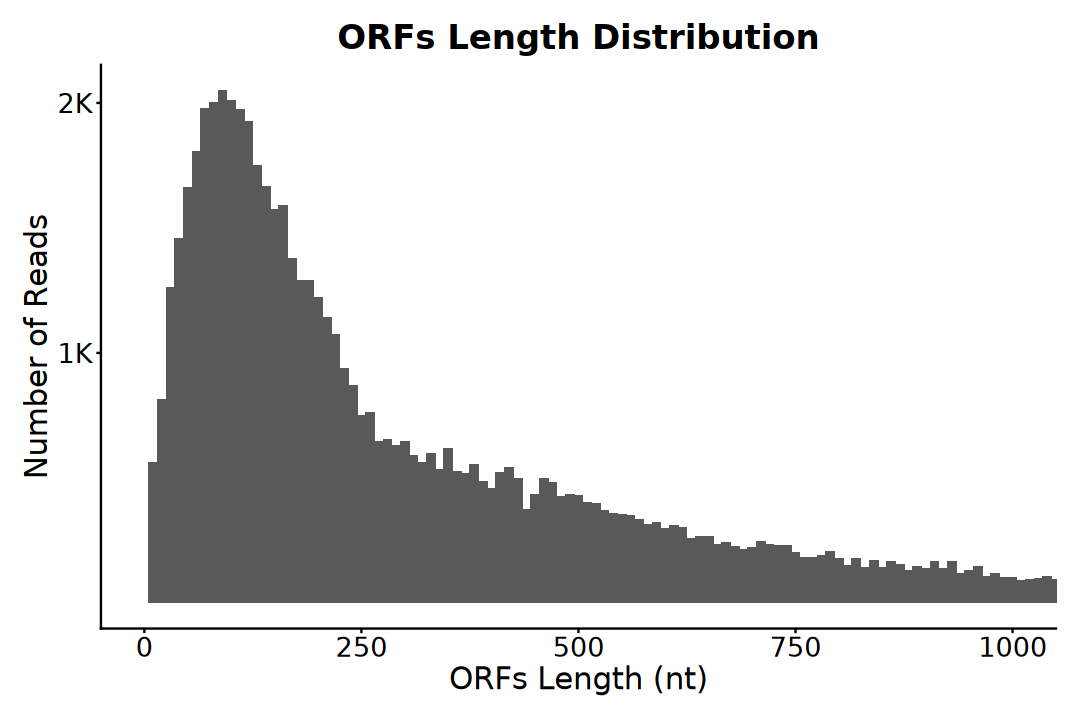

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(orfs, aes(x = AALen)) + 
    geom_histogram(binwidth = 10) + 
    scale_y_continuous(
        breaks = c(1e3, 2e3), 
        labels = scales::label_number(scale = 1e-3, suffix = "K") ) +
    coord_cartesian(xlim = c(0, 1000)) +
    labs(
        title = "ORFs Length Distribution",
        x = "ORFs Length (nt)", y = "Number of Reads") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [54]:
plot_df <- table(orfs$TisType) |> 
    as.data.frame(stringsAsFactors = FALSE) |> 
    setNames(c("Class", "Freq")) |>
    mutate(
        Class = factor(Class),
        Fraction = Freq / sum(Freq),
        Percent  = scales::percent(Fraction))

plot_df

Class,Freq,Fraction,Percent
<fct>,<int>,<dbl>,<chr>
3'UTR,83,0.0012771589,0.1277%
3'UTR:CDSFrameOverlap,2849,0.0438388626,4.3839%
3'UTR:Known,238,0.0036622146,0.3662%
5'UTR,1377,0.0211885271,2.1189%
5'UTR:CDSFrameOverlap,42,0.0006462732,0.0646%
5'UTR:Known,166,0.0025543177,0.2554%
Annotated,33333,0.5129100757,51.2910%
Extended,458,0.0070474549,0.7047%
Extended:CDSFrameOverlap,35,0.0005385610,0.0539%


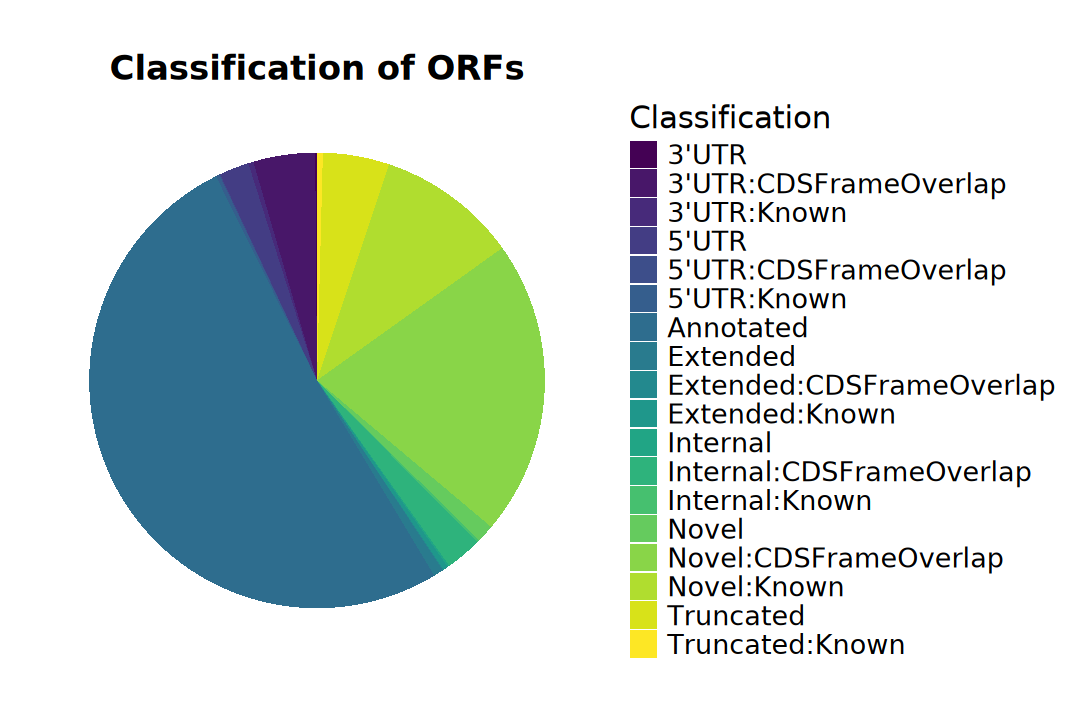

In [55]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = "", y = Freq, fill = Class)) + 
    geom_bar(width = 1, stat = "identity") +
    coord_polar("y", start = 0) +
    scale_fill_viridis_d() +
    labs(title = "Classification of ORFs", fill = "Classification") +
    theme_minimal() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid = element_blank(),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks = element_blank())

In [56]:
plot_df <- table(orfs$TisType) |> 
    as.data.frame(stringsAsFactors = FALSE) |> 
    setNames(c("Class", "Freq")) |>
    filter(str_detect(Class, "UTR|Novel")) |>
    mutate(
        Class = factor(Class),
        Fraction = Freq / sum(Freq),
        Percent  = scales::percent(Fraction))

plot_df

Class,Freq,Fraction,Percent
<fct>,<int>,<dbl>,<chr>
3'UTR,83,0.003225681,0.32%
3'UTR:CDSFrameOverlap,2849,0.110722475,11.07%
3'UTR:Known,238,0.009249543,0.92%
5'UTR,1377,0.053515215,5.35%
5'UTR:CDSFrameOverlap,42,0.001632272,0.16%
5'UTR:Known,166,0.006451362,0.65%
Novel,818,0.031790447,3.18%
Novel:CDSFrameOverlap,13655,0.530682834,53.07%
Novel:Known,6503,0.252730170,25.27%


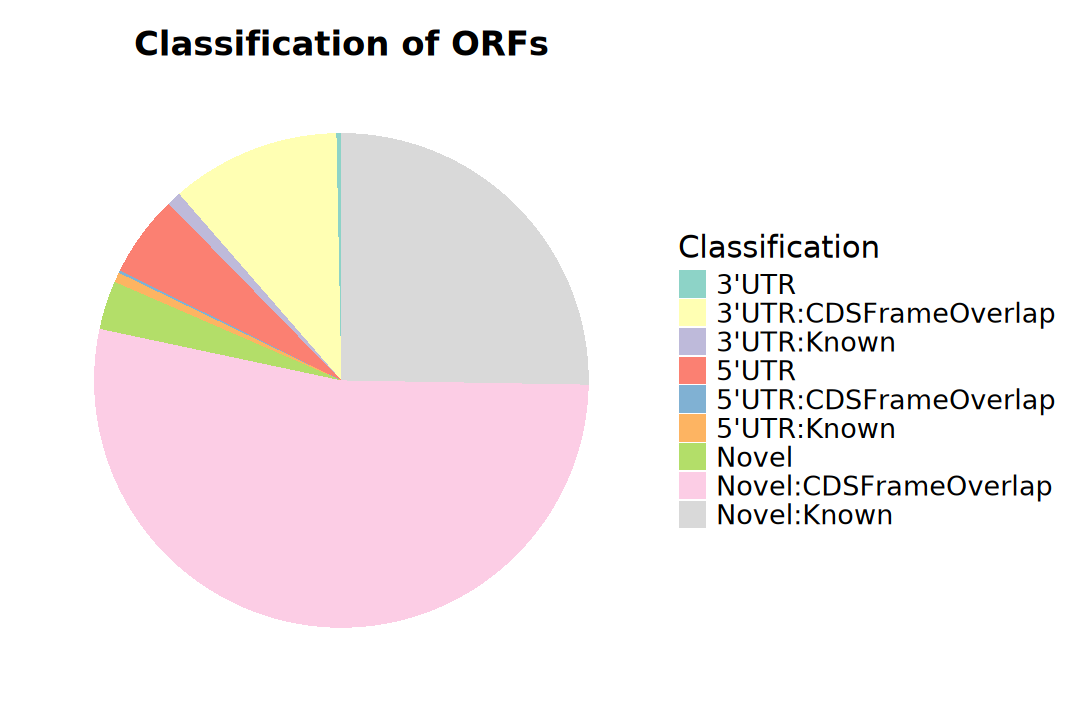

In [57]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = "", y = Freq, fill = Class)) + 
    geom_bar(width = 1, stat = "identity") +
    coord_polar("y", start = 0) +
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Classification of ORFs", fill = "Classification") +
    theme_minimal() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid = element_blank(),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks = element_blank())

In [58]:
# Output bed for IGV.
# prepared_df <- orfs |>
#     select(TisType, GenomePos, Tid) |>
#     separate(
#         GenomePos, into = c("chr", "start", "end", "strand"), 
#         sep = ":|-", remove = FALSE) |>
#     mutate(score = 0) |>
#     select(TisType, chr, start, end, Tid, score, strand)

# prepared_df |>
#     group_by(TisType) |>
#     group_walk(~ {
#         file_name <- paste0("06_ribotish/sample", .y$TisType, ".bed")
#         readr::write_delim(.x, file_name, delim = "\t", col_names = FALSE)
#     })

## b). [Ribotricer](https://github.com/smithlabcode/ribotricer)

In [59]:
orfs_files_list <- file.path(data_dir, "06_ribotricer") |>
    list.files("translating_ORFs.tsv", full.names = TRUE)

In [60]:
orfs <- data.table::fread(
    orfs_files_list[[1]], header = TRUE, sep = "\t", 
    drop = c("profile"))

head(orfs)

ORF_ID,ORF_type,status,phase_score,read_count,length,valid_codons,valid_codons_ratio,read_density,transcript_id,transcript_type,gene_id,gene_name,gene_type,chrom,strand,start_codon
<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ENSMUST00000070533.4_3216025_3671348_1941,annotated,translating,0.6542552,68,1941,43,0.06646059,0.10510046,ENSMUST00000070533.4,protein_coding,ENSMUSG00000051951.5,Xkr4,protein_coding,chr1,-,ATG
ENSMUST00000027035.9_4491719_4493406_1257,annotated,translating,0.8672175,12,1257,11,0.02625298,0.02863962,ENSMUST00000027035.9,protein_coding,ENSMUSG00000025902.13,Sox17,protein_coding,chr1,-,ATG
ENSMUST00000195555.1_4491719_4492591_873,annotated,translating,0.8196798,9,873,8,0.02749141,0.03092784,ENSMUST00000195555.1,protein_coding,ENSMUSG00000025902.13,Sox17,protein_coding,chr1,-,ATG
ENSMUST00000192650.5_4491719_4495155_1062,annotated,translating,0.6938887,11,1062,9,0.02542373,0.03107345,ENSMUST00000192650.5,protein_coding,ENSMUSG00000025902.13,Sox17,protein_coding,chr1,-,ATG
ENSMUST00000116652.7_4491719_4493406_1257,annotated,translating,0.8672175,12,1257,11,0.02625298,0.02863962,ENSMUST00000116652.7,protein_coding,ENSMUSG00000025902.13,Sox17,protein_coding,chr1,-,ATG
ENSMUST00000130201.7_4774455_4785677_612,annotated,translating,0.7581471,475,612,70,0.34313725,2.32843137,ENSMUST00000130201.7,protein_coding,ENSMUSG00000033845.13,Mrpl15,protein_coding,chr1,-,ATG


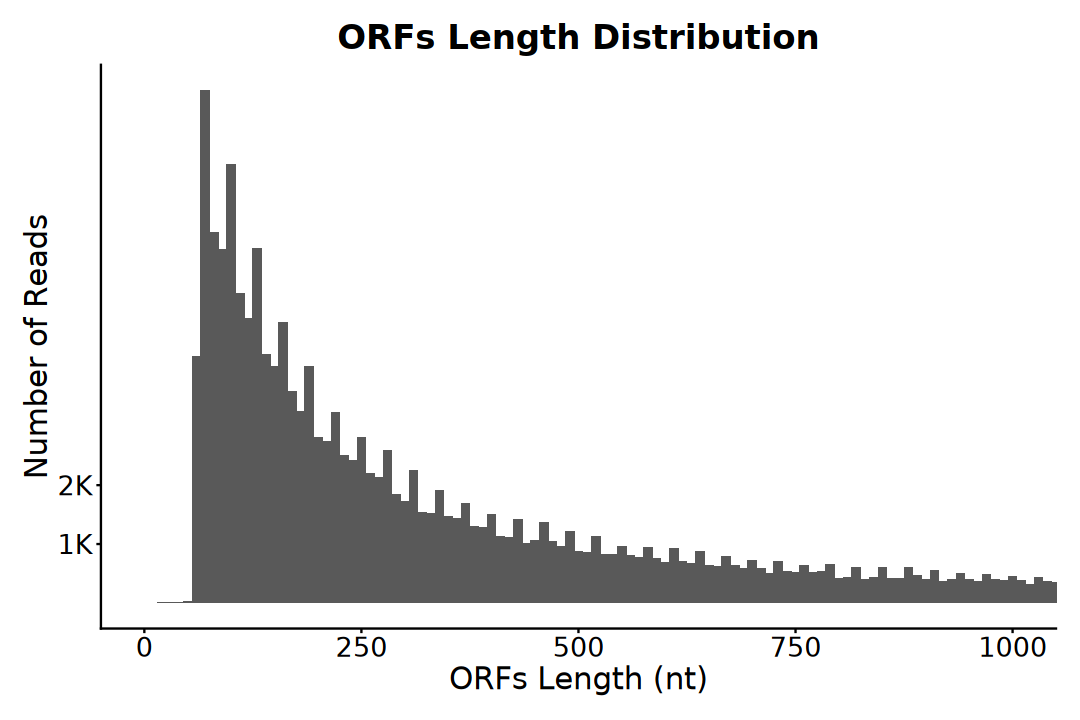

In [61]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(orfs, aes(x = length)) + 
    geom_histogram(binwidth = 10) + 
    scale_y_continuous(
        breaks = c(1e3, 2e3), 
        labels = scales::label_number(scale = 1e-3, suffix = "K") ) +
    coord_cartesian(xlim = c(0, 1000)) +
    labs(
        title = "ORFs Length Distribution",
        x = "ORFs Length (nt)", y = "Number of Reads") + 
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [62]:
plot_df <- table(orfs$ORF_type) |> 
    as.data.frame(stringsAsFactors = FALSE) |> 
    setNames(c("Class", "Freq")) |>
    mutate(
        Class = factor(Class),
        Fraction = Freq / sum(Freq),
        Percent  = scales::percent(Fraction))

plot_df

Class,Freq,Fraction,Percent
<fct>,<int>,<dbl>,<chr>
annotated,36158,0.184321602,18.43%
dORF,27532,0.140349089,14.03%
novel,111360,0.567676685,56.77%
overlap_dORF,13214,0.067360630,6.74%
overlap_uORF,2644,0.013478243,1.35%
super_dORF,1899,0.009680478,0.97%
super_uORF,2177,0.011097631,1.11%
uORF,1184,0.006035643,0.60%


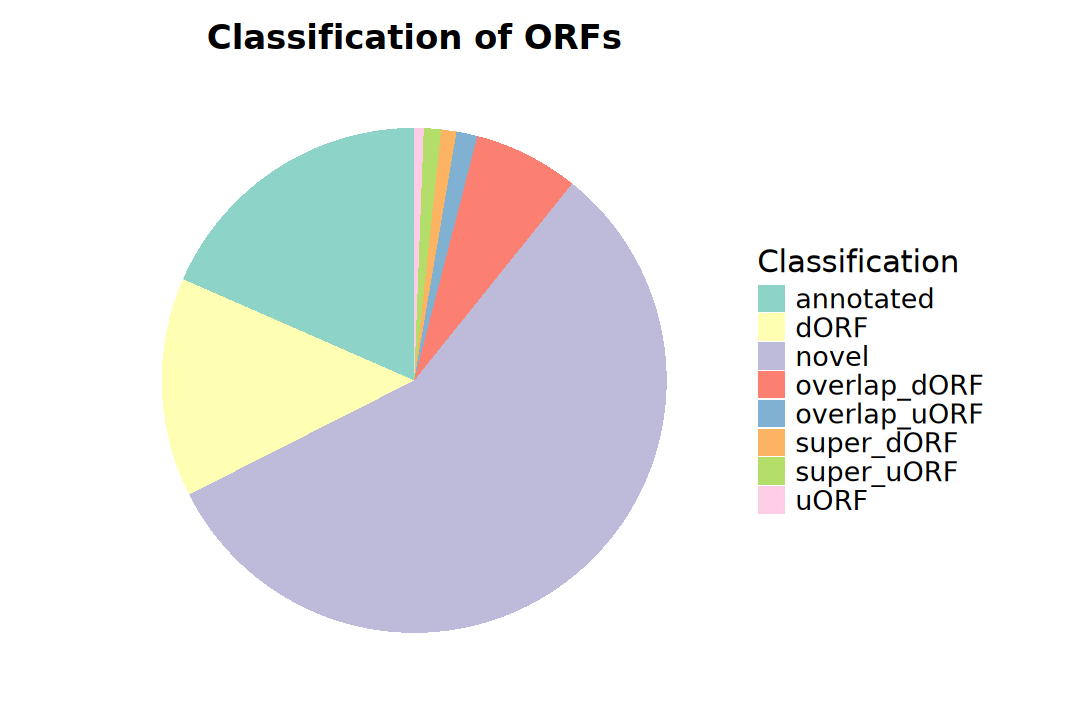

In [63]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = "", y = Freq, fill = Class)) + 
    geom_bar(width = 1, stat = "identity") +
    coord_polar("y", start = 0) +
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Classification of ORFs", fill = "Classification") +
    theme_minimal() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid = element_blank(),
        legend.title = element_text(size = 18), 
        legend.text= element_text(size = 16),
        axis.title = element_blank(),
        axis.text.x = element_blank(),
        axis.text.y = element_text(size = 16),
        axis.ticks = element_blank())